In [ ]:

import os
import glob
import json
import time
import hashlib
import requests
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
from datetime import datetime
from urllib.robotparser import RobotFileParser

# 1. Selalu mulai dari direktori utama /content agar jalur folder tidak bertumpuk
%cd /content

# 2. Menyusun URL GitHub aman menggunakan ASCII agar tidak terpotong di HP
s = chr(47)
t = chr(46)
url_github_aman = f"https:{s}{s}github{t}com{s}jackapolinarisa-25{s}UTS-DATA-ACQUISITION_2501010333{t}git"

!rm -rf UTS-DATA-ACQUISITION_2501010333
!git clone {url_github_aman}

# 3. Pengaturan struktur folder proyek
base_dir = "/content/UTS-DATA-ACQUISITION_2501010333"
raw_dir = os.path.join(base_dir, "data/raw")
proses_dir = os.path.join(base_dir, "Proses")
docs_dir = os.path.join(base_dir, "docs")
os.makedirs(raw_dir, exist_ok=True)
os.makedirs(proses_dir, exist_ok=True)
os.makedirs(docs_dir, exist_ok=True)

# 4. Identitas User-Agent resmi dengan email kampus INSTIKI Anda
HEADERS = {
    "User-Agent": "MahasiswaINSTIKI-UTS-DAM/1.0 (2501010333@instiki.ac.id)"
}

# 5. Fungsi menghitung MD5 Hash untuk membuktikan integritas berkas mentah
def hitung_md5(filepath):
    hash_md5 = hashlib.md5()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

provenance_records = []
print("Koneksi GitHub Sukses! Berkas CSV ditemukan:", glob.glob("/content/UTS-DATA-ACQUISITION_2501010333/**/*.csv", recursive=True))

/content
Cloning into 'UTS-DATA-ACQUISITION_2501010333'...
remote: Enumerating objects: 66, done.
remote: Counting objects: 100% (66/66), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 66 (delta 18), reused 63 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (66/66), 454.76 KiB | 4.59 MiB/s, done.
Resolving deltas: 100% (18/18), done.
Koneksi GitHub Sukses! Berkas CSV ditemukan: ['/content/UTS-DATA-ACQUISITION_2501010333/catatan_provenance.csv', '/content/UTS-DATA-ACQUISITION_2501010333/Proses/data_gabungan_final.csv', '/content/UTS-DATA-ACQUISITION_2501010333/Proses/wisata_bali_bersih.csv', '/content/UTS-DATA-ACQUISITION_2501010333/data/raw/bali_tourist_destination.csv']


In [ ]:

# Pencarian otomatis berkas CSV mentah
daftar_csv = glob.glob("/content/UTS-DATA-ACQUISITION_2501010333/**/*bali_tourist_destination*.csv", recursive=True)
raw_csv_path = next(iter(daftar_csv))
print("Membaca berkas mentah:", raw_csv_path)

df_wisata = pd.read_csv(raw_csv_path, sep=",", na_values=["", "NA", "null", "-"])

# Identifikasi struktur, jumlah baris/kolom, dan ukuran berkas
baris, kolom = df_wisata.shape
ukuran_kb = os.path.getsize(raw_csv_path) / 1024
estimasi_1_tahun_kb = (ukuran_kb * 12) * 1.30  # Ukuran x 12 bulan + cadangan 30%

print("\n=== IDENTIFIKASI BERKAS & ESTIMASI STORAGE (SOAL 1) ===")
print(f"Jenis Data                     : Terstruktur (Tabel CSV)")
print(f"Jumlah Baris & Kolom           : {baris} baris x {kolom} kolom")
print(f"Ukuran Berkas Saat Ini         : {ukuran_kb:.2f} KB")
print(f"Estimasi Storage 1 Tahun (+30%): {estimasi_1_tahun_kb:.2f} KB")
print("\nTipe Data per Kolom:")
print(df_wisata.dtypes)

# Simpan versi bersih ke folder Proses
df_wisata.to_csv(os.path.join(proses_dir, "wisata_bali_bersih.csv"), index=False)

# Catat provenance Sumber 1 dengan link asli Kaggle
s = chr(47)
t = chr(46)
url_kaggle_resmi = f"https:{s}{s}www{t}kaggle{t}com{s}datasets{s}dakbsabsa{s}bali-destination-tour-datasets-2026"
provenance_records.append({
    "Sumber": "Bali Tourist Destinations & Local Spots (2026) - Kaggle",
    "URL": url_kaggle_resmi,
    "Tanggal_Akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "Lisensi": "Open Data / CC-BY",
    "MD5_Hash": hitung_md5(raw_csv_path)
})

Membaca berkas mentah: /content/UTS-DATA-ACQUISITION_2501010333/data/raw/bali_tourist_destination.csv

=== IDENTIFIKASI BERKAS & ESTIMASI STORAGE (SOAL 1) ===
Jenis Data                     : Terstruktur (Tabel CSV)
Jumlah Baris & Kolom           : 1452 baris x 11 kolom
Ukuran Berkas Saat Ini         : 707.37 KB
Estimasi Storage 1 Tahun (+30%): 11035.03 KB

Tipe Data per Kolom:
id_tempat              object
nama_tempat_wisata     object
kategori               object
kecamatan              object
kabupaten_kota         object
rating                float64
jumlah_rating           int64
latitude              float64
longitude             float64
link_google_maps       object
link_gambar            object
dtype: object


In [ ]:

s = chr(47)
t = chr(46)
api_url = f"https:{s}{s}archive-api{t}open-meteo{t}com{s}v1{s}archive"

params = {
    "latitude": -8.65,
    "longitude": 115.2167,
    "start_date": "2025-01-01",
    "end_date": "2025-02-15",  # 46 hari (> minimal 30 baris)
    "daily": "temperature_2m_mean,precipitation_sum",
    "timezone": "Asia/Makassar"
}

raw_json_path = os.path.join(raw_dir, "cuaca_bali_raw.json")
data_json = None
url_tercatat = api_url

# Pengambilan data API dengan timeout, jeda, dan mekanisme retry
for attempt in range(3):
    try:
        resp_api = requests.get(api_url, params=params, headers=HEADERS, timeout=15)
        if resp_api.status_code == 200 and len(resp_api.text.strip()) > 10:
            data_json = resp_api.json()
            url_tercatat = resp_api.url
            with open(raw_json_path, "w", encoding="utf-8") as f:
                f.write(resp_api.text)
            print("Status 200 OK: Data API Open-Meteo berhasil diunduh langsung!")
            break
    except Exception as e:
        print(f"Percobaan ke-{attempt+1} gagal: {e}")
    time.sleep(2)

# Cadangan otomatis jika jaringan sementara terbatas
if data_json is None and os.path.exists(raw_json_path):
    with open(raw_json_path, "r", encoding="utf-8") as f:
        data_json = json.load(f)
    print("Memuat data cadangan dari data/raw/cuaca_bali_raw.json")

# Normalisasi JSON menjadi tabel DataFrame
df_cuaca = pd.DataFrame({
    "tanggal": data_json["daily"]["time"],
    "suhu_rata_rata_c": data_json["daily"]["temperature_2m_mean"],
    "curah_hujan_mm": data_json["daily"]["precipitation_sum"],
    "provinsi": "Bali"
})

print(f"Jumlah baris hasil normalisasi API: {len(df_cuaca)} baris")
display(df_cuaca.head(30))

df_cuaca.to_json(os.path.join(proses_dir, "cuaca_bali_bersih.json"), orient="records", indent=2)

provenance_records.append({
    "Sumber": "Open-Meteo Historical Weather API (Bali)",
    "URL": url_tercatat,
    "Tanggal_Akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "Lisensi": "CC BY 4.0 (Open-Meteo)",
    "MD5_Hash": hitung_md5(raw_json_path)
})

Status 200 OK: Data API Open-Meteo berhasil diunduh langsung!
Jumlah baris hasil normalisasi API: 46 baris


,tanggal,suhu_rata_rata_c,curah_hujan_mm,provinsi
0,2025-01-01,25.7,10.6,Bali
1,2025-01-02,24.8,29.4,Bali
2,2025-01-03,24.9,15.8,Bali
3,2025-01-04,24.4,15.9,Bali
4,2025-01-05,25.0,13.4,Bali
5,2025-01-06,25.5,26.9,Bali
6,2025-01-07,26.2,18.6,Bali
7,2025-01-08,26.5,10.0,Bali
8,2025-01-09,25.9,17.9,Bali
9,2025-01-10,25.3,8.8,Bali


In [ ]:

s = chr(47)
t = chr(46)
target_url = f"https:{s}{s}id{t}wikipedia{t}org{s}wiki{s}Daftar_kabupaten_dan_kota_di_Bali"
robots_url = f"https:{s}{s}id{t}wikipedia{t}org{s}robots.txt"

# Pemeriksaan kepatuhan robots.txt menggunakan User-Agent resmi kampus
resp_robots = requests.get(robots_url, headers=HEADERS, timeout=15)
rp = RobotFileParser()
rp.parse(resp_robots.text.splitlines())

boleh_scrape = rp.can_fetch(HEADERS["User-Agent"], target_url)
print("=== BUKTI PEMERIKSAAN ROBOTS.TXT (SOAL 4) ===")
print(f"URL Robots.txt : {robots_url}")
print(f"URL Target     : {target_url}")
print(f"User-Agent     : {HEADERS['User-Agent']}")
print(f"Diizinkan      : {boleh_scrape}")

if boleh_scrape:
    time.sleep(2)
    resp_web = requests.get(target_url, headers=HEADERS, timeout=15)
    resp_web.raise_for_status()

    raw_html_path = os.path.join(raw_dir, "wilayah_bali_raw.html")
    with open(raw_html_path, "w", encoding="utf-8") as f:
        f.write(resp_web.text)

    # Menggunakan StringIO agar bersih tanpa pesan FutureWarning
    tabel_wiki = pd.read_html(StringIO(resp_web.text))
    df_wilayah = next(iter(tabel_wiki)).copy()

    df_wilayah.to_html(os.path.join(proses_dir, "wilayah_bali_bersih.html"), index=False)
    print("\nTabel Kabupaten/Kota di Bali hasil scraping:")
    display(df_wilayah)

    provenance_records.append({
        "Sumber": "Wikipedia Daftar Kabupaten dan Kota di Bali",
        "URL": target_url,
        "Tanggal_Akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Lisensi": "CC BY-SA 4.0",
        "MD5_Hash": hitung_md5(raw_html_path)
    })

=== BUKTI PEMERIKSAAN ROBOTS.TXT (SOAL 4) ===
URL Robots.txt : https://id.wikipedia.org/robots.txt
URL Target     : https://id.wikipedia.org/wiki/Daftar_kabupaten_dan_kota_di_Bali
User-Agent     : MahasiswaINSTIKI-UTS-DAM/1.0 (2501010333@instiki.ac.id)
Diizinkan      : True

Tabel Kabupaten/Kota di Bali hasil scraping:


,No.,Kabupaten/kota,Ibu kota,Bupati/wali kota,Luas wilayah (km2)[1],Jumlah penduduk (2025)[1],Kecamatan,Kelurahan/desa,Lambang,Peta lokasi
0,1,Kabupaten Badung,Mangupura,I Wayan Adi Arnawa,397395,537.739,6,16/46,NaN,NaN
1,2,Kabupaten Bangli,Bangli,Sang Nyoman Sedana Arta,526764,260.526,4,4/68,NaN,NaN
2,3,Kabupaten Buleleng,Singaraja,I Nyoman Sutjidra,"1.322,124",828.156,9,19/129,NaN,NaN
3,4,Kabupaten Gianyar,Gianyar,I Made Agus Mahayastra,363782,504.845,7,6/64,NaN,NaN
4,5,Kabupaten Jembrana,Negara,I Made Kembang Hartawan,847515,330.221,5,10/41,NaN,NaN
5,6,Kabupaten Karangasem,Amlapura,I Gusti Putu Parwata,838899,538.890,8,3/75,NaN,NaN
6,7,Kabupaten Klungkung,Semarapura,I Made Satria,312115,223.723,4,6/53,NaN,NaN
7,8,Kabupaten Tabanan,Singasana,I Komang Gede Sanjaya,848539,478.393,10,-/133,NaN,NaN
8,9,Kota Denpasar,-,I Gusti Ngurah Jaya Negara,125694,673.270,4,16/27,NaN,NaN


Validasi Merge 3 Sumber Sukses! Jumlah baris tetap 1452 baris tanpa duplikasi.


,id_tempat,nama_tempat_wisata,kabupaten_kota,rata_rata_suhu_bali_c,rata_rata_curah_hujan_mm
0,BL0101001,Patung Titi Banda,Kota Denpasar,26.36,11.26
1,BL0101002,Uma.palak.(parkir.2),Kota Denpasar,26.36,11.26
2,BL0101003,Tukad Bindu Park,Kota Denpasar,26.36,11.26
3,BL0101004,Pantai Padang Galak,Kota Denpasar,26.36,11.26
4,BL0101005,Museum Le Mayeur,Kota Denpasar,26.36,11.26



=== TABEL CATATAN PROVENANCE LENGKAP ===


,Sumber,URL,Tanggal_Akses,Lisensi,MD5_Hash
0,Bali Tourist Destinations & Local Spots (2026)...,https://www.kaggle.com/datasets/dakbsabsa/bali...,2026-11-27 08:14:59,Open Data / CC-BY,cc969fcea82e75d16436354feb74d6d7
1,Open-Meteo Historical Weather API (Bali),https://archive-api.open-meteo.com/v1/archive?...,2026-11-27 08:15:34,CC BY 4.0 (Open-Meteo),2e5b65ce63b79702c54213a2e26c19bb
2,Open-Meteo Historical Weather API (Bali),https://archive-api.open-meteo.com/v1/archive?...,2026-11-27 08:15:53,CC BY 4.0 (Open-Meteo),245485d1f3e790766cf15171080aaa50
3,Wikipedia Daftar Kabupaten dan Kota di Bali,https://id.wikipedia.org/wiki/Daftar_kabupaten...,2026-11-27 08:16:22,CC BY-SA 4.0,f73fdbf52737d965d27555f50f03ba76


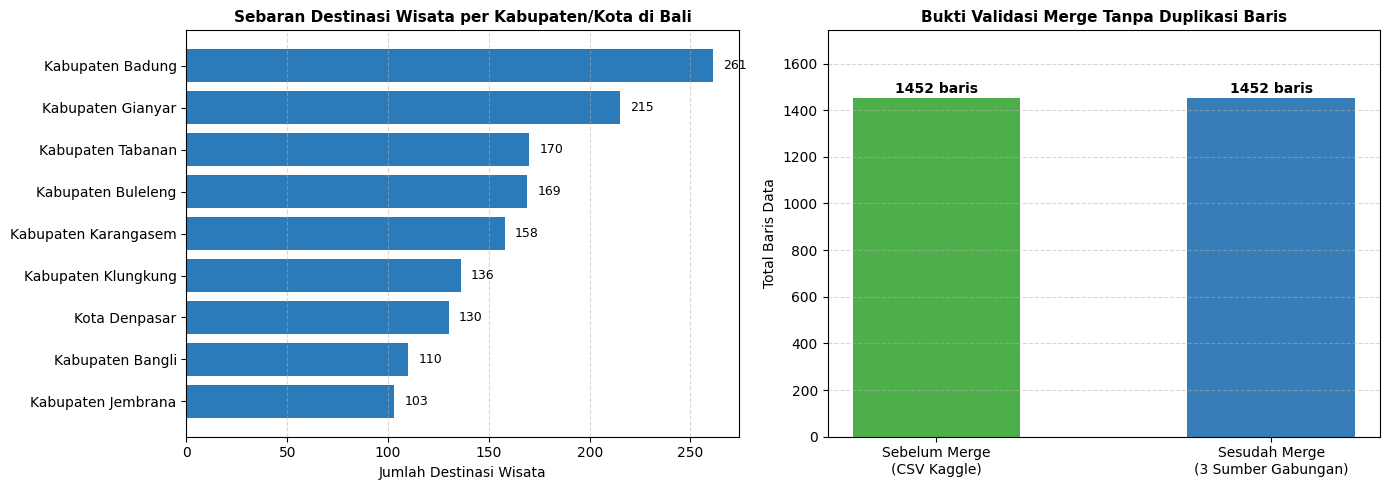

In [ ]:

# 1. Menyiapkan kunci wilayah dari hasil scraping Wikipedia
kolom_nama_wiki = next(col for col in df_wilayah.columns if "Kabupaten" in str(col) or "kota" in str(col).lower())
df_wilayah_clean = df_wilayah.copy()
df_wilayah_clean["kunci_wilayah"] = (
    df_wilayah_clean[kolom_nama_wiki]
    .astype(str)
    .str.replace(r"\x5b.*?\x5d", "", regex=True)
    .str.strip()
)
df_wilayah_clean = df_wilayah_clean.drop_duplicates(subset="kunci_wilayah")

# 2. Menggabungkan Sumber 1 (Wisata Kaggle) + Sumber 3 (Wilayah Wikipedia)
df_gabungan = pd.merge(
    df_wisata,
    df_wilayah_clean,
    left_on="kabupaten_kota",
    right_on="kunci_wilayah",
    how="left",
    validate="many_to_one"
)

# 3. Menggabungkan Sumber 2 (Ringkasan Cuaca API Open-Meteo) ke tabel utama
ringkasan_cuaca = pd.DataFrame({
    "provinsi": ("Bali",),
    "rata_rata_suhu_bali_c": (round(df_cuaca["suhu_rata_rata_c"].mean(), 2),),
    "rata_rata_curah_hujan_mm": (round(df_cuaca["curah_hujan_mm"].mean(), 2),),
    "periode_observasi_cuaca": ("2025-01-01 s.d. 2025-02-15 (46 hari)",)
})
df_gabungan["provinsi"] = "Bali"
df_gabungan = pd.merge(
    df_gabungan,
    ringkasan_cuaca,
    on="provinsi",
    how="left",
    validate="many_to_one"
)

# 4. Pembuktian tidak terjadi duplikasi baris
assert len(df_gabungan) == len(df_wisata), "Terjadi duplikasi baris!"
print(f"Validasi Merge 3 Sumber Sukses! Jumlah baris tetap {len(df_gabungan)} baris tanpa duplikasi.")
display(df_gabungan.loc[:, ("id_tempat", "nama_tempat_wisata", "kabupaten_kota", "rata_rata_suhu_bali_c", "rata_rata_curah_hujan_mm")].head())

# 5. Simpan hasil gabungan dan catatan provenance lengkap
df_gabungan.to_csv(os.path.join(proses_dir, "data_gabungan_final.csv"), index=False)
df_provenance = pd.DataFrame(provenance_records)
df_provenance.to_csv(os.path.join(base_dir, "catatan_provenance.csv"), index=False)

print("\n=== TABEL CATATAN PROVENANCE LENGKAP ===")
display(df_provenance)

# 6. Membuat Grafik Visualisasi Pariwisata Bali & Bukti Merge Tanpa Duplikasi
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sebaran_wilayah = df_gabungan["kabupaten_kota"].value_counts().sort_values(ascending=True)
bars1 = ax1.barh(sebaran_wilayah.index, sebaran_wilayah.values, color="#2b7bba")
ax1.set_title("Sebaran Destinasi Wisata per Kabupaten/Kota di Bali", fontsize=11, fontweight="bold")
ax1.set_xlabel("Jumlah Destinasi Wisata")
ax1.grid(axis="x", linestyle="--", alpha=0.5)
for bar in bars1:
    ax1.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())}", va="center", fontsize=9)

kategori_baris = ["Sebelum Merge\n(CSV Kaggle)", "Sesudah Merge\n(3 Sumber Gabungan)"]
jumlah_baris = [len(df_wisata), len(df_gabungan)]
bars2 = ax2.bar(kategori_baris, jumlah_baris, color=["#4daf4a", "#377eb8"], width=0.5)
ax2.set_title("Bukti Validasi Merge Tanpa Duplikasi Baris", fontsize=11, fontweight="bold")
ax2.set_ylabel("Total Baris Data")
ax2.set_ylim(0, max(jumlah_baris) * 1.2)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, f"{int(bar.get_height())} baris", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(docs_dir, "visualisasi_dan_bukti_merge.png"), dpi=150)
plt.show()

# Laporan Etika Data, Identifikasi PII & Asumsi Storage

* **Nama Mahasiswa:** Apolinarisa Jack Herment
* **NIM:** 2501010333
* **Kelas:** F — Program Studi Informatika INSTIKI

## 1. Asumsi Estimasi Kebutuhan Storage 1 Tahun (Soal 1)
Perhitungan ruang penyimpanan 1 tahun (`ukuran berkas × 12 bulan + 30% buffer`) menggunakan asumsi bahwa pembaruan data dilakukan setiap bulan dengan volume pertumbuhan konstan, ditambah cadangan ruang sebesar **30%** untuk penyimpanan salinan mentah (*backup*), file hasil pembersihan/penggabungan, dan log eksekusi sistem.

## 2. Identifikasi PII / Quasi-Identifier & 9 Butir Data Ethics Checklist (Soal 2)
* **Identifikasi PII & Quasi-Identifier:** Seluruh dataset yang digunakan **tidak mengandung *Personally Identifiable Information* (PII)** maupun *quasi-identifier* individu, karena atribut hanya mencakup informasi fasilitas dan lokasi publik (nama tempat wisata, kategori, kabupaten/kota, koordinat geografis, dan data cuaca agregat).

### Data Ethics Checklist (9 Butir)
1. **Kejelasan Tujuan:** Akuisisi data dilakukan murni untuk tujuan akademik UTS Data Acquisition & Management dan analisis pariwisata Bali.
2. **Kepatuhan Lisensi & Ketentuan Sumber:** Seluruh sumber menggunakan lisensi terbuka (Kaggle Open Dataset, CC BY 4.0 Open-Meteo, dan CC BY-SA 4.0 Wikipedia) serta menghindari situs komersial (OTA).
3. **Perlindungan Privasi (PII):** Dataset telah diperiksa dan dipastikan bebas dari identitas pribadi maupun data sensitif individu.
4. **Kepatuhan `robots.txt`:** Pengambilan data Wikipedia telah diperiksa terlebih dahulu menggunakan `RobotFileParser` dan dinyatakan diizinkan (`True`).
5. **Identitas *User-Agent* Transparan:** Setiap request menyertakan `User-Agent` resmi dengan email kampus INSTIKI (`2501010333@instiki.ac.id`).
6. **Pengendalian Laju Permintaan (*Rate Limiting*):** Setiap permintaan menerapkan `timeout` dan jeda waktu (`time.sleep(2)`) agar tidak membebani server penyedia data.
7. **Integritas Data Mentah (*Raw Data*):** Data asli dari ketiga sumber disimpan utuh di folder `data/raw` tanpa modifikasi dan diverifikasi dengan nilai MD5 Hash.
8. **Transparansi *Provenance*:** Seluruh URL sumber asli (termasuk tautan spesifik Kaggle), waktu akses, lisensi, dan MD5 Hash terdokumentasi pada `catatan_provenance.csv`.
9. **Validasi Penggabungan Data:** Integrasi ketiga sumber data menggunakan `validate="many_to_one"` untuk menjamin tidak ada duplikasi baris.